# Corretor automático de provas por gabarito (OMR)

Notebook de referência para gerar uma folha-resposta, retificar fotos, ler RA manuscrito e respostas, calcular notas e produzir saídas visuais e estatísticas. O fluxo usa OpenCV e NumPy no processamento principal, com pandas e Matplotlib para resultados.

> **Avaliação:** a seção de demonstração cria 30 imagens fotográficas sintéticas com perspectiva, iluminação, ruído e desfoque para exercitar o avaliador automaticamente. Isso valida o pipeline em condições controladas, mas não deve ser apresentado como 30 fotos reais. Para cumprir literalmente a coleta de campo, substitua/adapte a seção de avaliação com pelo menos 30 fotos reais e registre dispositivo e condição de captura. Não use dados pessoais reais sem consentimento.

A folha possui marcadores quadrados nos cantos, grade de bolhas e campo manuscrito `RA:____________`. O contorno externo é localizado com Canny e aproximação poligonal. A leitura do RA segmenta os algarismos com OpenCV e classifica cada caractere com um SVM treinado no conjunto manuscrito `load_digits` do scikit-learn. A demonstração sintética imprime o RA com uma fonte; ela não mede a precisão com escrita manual real.

In [2]:
# Em Colab, descomente se necessário:
# No Colab, instale as dependencias se necessario:
# !pip -q install opencv-python-headless pandas matplotlib scikit-learn
# Se sklearn apresentar ImportError por instalacao inconsistente, execute em uma celula: %pip install --upgrade --force-reinstall --no-cache-dir scikit-learn
# Depois reinicie o kernel e execute o notebook novamente.
import cv2 
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import random, math, os
from sklearn.datasets import load_digits
from sklearn.svm import SVC

print('OpenCV:', cv2.__version__)

OpenCV: 5.1.0


## 1. Parâmetros e gabarito
As dimensões estão em pixels para uma folha A4 vertical em resolução de impressão. Os mesmos parâmetros definem desenho e leitura, evitando coordenadas divergentes.

In [3]:
W, H = 1654, 2339  # aproximadamente A4 a 200 dpi
N_QUESTOES, N_OPCOES = 20, 5
OPCOES = list('ABCDE')
GABARITO = ['A','C','B','D','E','A','B','C','D','E',
             'B','A','D','C','E','B','C','A','D','E']
PONTOS_PAGINA = np.float32([[0,0],[W-1,0],[W-1,H-1],[0,H-1]])

# Regiões de layout (coordenadas canônicas).
RA_ROI = (355, 325, 1470, 380)  # x1, y1, x2, y2 na folha retificada
GRID_X0, GRID_Y0, COL_DX, ROW_DY = 310, 1000, 205, 59
RAIO = 19

def centro_bolha_questao(q, opcao):
    return (GRID_X0 + opcao * COL_DX, GRID_Y0 + q * ROW_DY)



## 2. Geração programática da folha
O desenho usa tons de cinza, linhas, texto e círculos. O PNG pode ser impresso em A4 sem redimensionamento (100%); mantenha a folha inteira visível e evite reflexos. Os quatro quadrados pretos são marcadores fiduciais impressos.

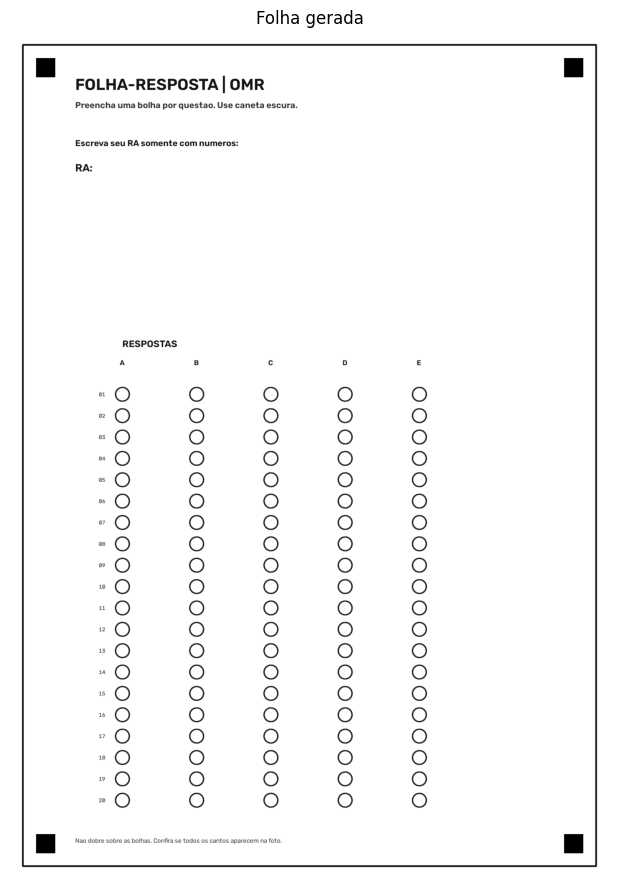

In [4]:
def gerar_folha():
    img = np.full((H, W, 3), 255, np.uint8)
    cv2.rectangle(img, (35,35), (W-36,H-36), (25,25,25), 3)
    # Fiduciais quadrados nos quatro cantos, dentro da borda.
    s, m = 52, 72
    for x,y in [(m,m),(W-m-s,m),(W-m-s,H-m-s),(m,H-m-s)]:
        cv2.rectangle(img,(x,y),(x+s,y+s),(0,0,0),-1)
    cv2.putText(img,'FOLHA-RESPOSTA | OMR',(180,160),cv2.FONT_HERSHEY_SIMPLEX,1.5,(20,20,20),3,cv2.LINE_AA)
    cv2.putText(img,'Preencha uma bolha por questao. Use caneta escura.',(180,210),cv2.FONT_HERSHEY_SIMPLEX,.8,(50,50,50),2,cv2.LINE_AA)
    cv2.putText(img,'Escreva seu RA somente com numeros:',(180,315),cv2.FONT_HERSHEY_SIMPLEX,.8,(20,20,20),2,cv2.LINE_AA)
    cv2.putText(img,'RA:',(180,385),cv2.FONT_HERSHEY_SIMPLEX,1.0,(20,20,20),2,cv2.LINE_AA)
    cv2.putText(img,'RESPOSTAS',(GRID_X0,870),cv2.FONT_HERSHEY_SIMPLEX,.9,(20,20,20),2,cv2.LINE_AA)
    for a,ch in enumerate(OPCOES):
        x=GRID_X0+a*COL_DX; cv2.putText(img,ch,(x-7,920),cv2.FONT_HERSHEY_SIMPLEX,.65,(30,30,30),2,cv2.LINE_AA)
    for q in range(N_QUESTOES):
        y=GRID_Y0+q*ROW_DY; cv2.putText(img,f'{q+1:02d}',(GRID_X0-65,y+6),cv2.FONT_HERSHEY_SIMPLEX,.52,(40,40,40),1,cv2.LINE_AA)
        for a in range(N_OPCOES): cv2.circle(img,centro_bolha_questao(q,a),RAIO,(30,30,30),2,cv2.LINE_AA)
    cv2.putText(img,'Nao dobre sobre as bolhas. Confira se todos os cantos aparecem na foto.',(180,H-100),cv2.FONT_HERSHEY_SIMPLEX,.6,(60,60,60),1,cv2.LINE_AA)
    return img

folha = gerar_folha()
Path('folha_resposta.png').write_bytes(cv2.imencode('.png',folha)[1].tobytes())
plt.figure(figsize=(8,11)); plt.imshow(cv2.cvtColor(folha,cv2.COLOR_BGR2RGB)); plt.axis('off'); plt.title('Folha gerada'); plt.show()

## 3. Localização e retificação por homografia
A imagem passa para escala de cinza e recebe equalização de histograma para melhorar contraste. Canny destaca bordas; a aproximação poligonal procura o maior quadrilátero plausível. A homografia mapeia seus quatro vértices para o retângulo canônico. Se não for possível detectar uma folha, o código retorna erro claro para revisar a foto. A ordem dos pontos é determinada por soma/diferença das coordenadas e pressupõe uma folha aproximadamente vertical.

In [5]:
def ordenar_pontos(pts):
    pts=np.asarray(pts,dtype=np.float32); out=np.zeros((4,2),np.float32)
    s=pts.sum(axis=1); d=np.diff(pts,axis=1).ravel()
    out[0]=pts[np.argmin(s)]; out[2]=pts[np.argmax(s)]
    out[1]=pts[np.argmin(d)]; out[3]=pts[np.argmax(d)]
    return out

def localizar_folha(imagem):
    cinza=cv2.cvtColor(imagem,cv2.COLOR_BGR2GRAY) if imagem.ndim==3 else imagem.copy()
    eq=cv2.equalizeHist(cinza)
    suave=cv2.GaussianBlur(eq,(5,5),0)
    bordas=cv2.Canny(suave,50,150)
    contornos,_=cv2.findContours(bordas,cv2.RETR_LIST,cv2.CHAIN_APPROX_SIMPLE)
    candidatos=sorted(contornos,key=cv2.contourArea,reverse=True)[:30]
    quad=None; area_min=imagem.shape[0]*imagem.shape[1]*.12
    for c in candidatos:
        if cv2.contourArea(c)<area_min: continue
        p=cv2.approxPolyDP(c,.02*cv2.arcLength(c,True),True)
        if len(p)==4 and cv2.isContourConvex(p): quad=ordenar_pontos(p.reshape(4,2)); break
    if quad is None: raise ValueError('Folha nao encontrada: enquadre os quatro cantos e tente novamente.')
    dst=np.float32([[0,0],[W-1,0],[W-1,H-1],[0,H-1]])
    M=cv2.getPerspectiveTransform(quad,dst)
    retificada=cv2.warpPerspective(imagem,M,(W,H),flags=cv2.INTER_CUBIC,borderMode=cv2.BORDER_REPLICATE)
    return retificada, {'cinza':cinza,'equalizada':eq,'suave':suave,'bordas':bordas,'quadrilatero':quad}

def mostrar_etapas(entrada, etapas, retificada):
    fig,axs=plt.subplots(1,5,figsize=(18,5))
    axs[0].imshow(cv2.cvtColor(entrada,cv2.COLOR_BGR2RGB)); axs[0].set_title('Foto')
    axs[1].imshow(etapas['equalizada'],cmap='gray'); axs[1].set_title('Cinza + equalizacao')
    axs[2].imshow(etapas['bordas'],cmap='gray'); axs[2].set_title('Canny')
    cont=entrada.copy(); cv2.polylines(cont,[etapas['quadrilatero'].astype(int)],True,(0,0,255),8)
    axs[3].imshow(cv2.cvtColor(cont,cv2.COLOR_BGR2RGB)); axs[3].set_title('Quadrilatero detectado')
    axs[4].imshow(cv2.cvtColor(retificada,cv2.COLOR_BGR2RGB)); axs[4].set_title('Homografia')
    for ax in axs: ax.axis('off')
    plt.tight_layout(); plt.show()

## 4. Limiarização e leitura das bolhas
A limiarização adaptativa gaussiana (invertida) segmenta tinta escura mesmo com variação suave de iluminação. A medida em cada bolha é a fração de pixels escuros em um disco interno. Nenhuma opção acima do limite é branco; várias opções são dupla marcação.

### Leitura manuscrita do RA
O campo é recortado por coordenadas após a retificação. O OpenCV amplia e binariza o recorte, segmenta os componentes dos algarismos diretamente no campo sem linha. Cada componente é redimensionado para 8×8 pixels e classificado por um SVM treinado no conjunto de dígitos manuscritos `load_digits` do scikit-learn. O reconhecimento pode falhar se os algarismos se tocarem, forem escritos fora da linha, estiverem apagados ou tiverem formato muito diferente dos exemplos de treino; calibrar e medir com RAs manuscritos reais é necessário.

In [6]:
def binarizar(retificada):
    cinza=cv2.cvtColor(retificada,cv2.COLOR_BGR2GRAY) if retificada.ndim==3 else retificada
    # bloco ímpar; C controla o deslocamento do limiar local
    return cv2.adaptiveThreshold(cinza,255,cv2.ADAPTIVE_THRESH_GAUSSIAN_C,cv2.THRESH_BINARY_INV,41,12)

def proporcao_tinta(binaria, centro, raio=11):
    x,y=centro; mascara=np.zeros(binaria.shape,np.uint8); cv2.circle(mascara,(int(x),int(y)),raio,255,-1)
    pixels=binaria[mascara>0]
    return float(np.count_nonzero(pixels))/max(len(pixels),1)

LIMIAR_MARCA=.28

def classificar(valores, limite=LIMIAR_MARCA):
    indices=[i for i,v in enumerate(valores) if v>=limite]
    if not indices: return 'BRANCO'
    if len(indices)>1: return 'DUPLA'
    return indices[0]

# O SVC usa o conjunto load_digits do scikit-learn (digitos manuscritos 8x8).
# A classificacao e auxiliar; a separacao dos caracteres e feita com OpenCV.
_base=load_digits()
_MODELO_DIGITOS=SVC(kernel='rbf',gamma='scale').fit(_base.data,_base.target)

def preparar_digito(imagem_binaria):
    ys,xs=np.where(imagem_binaria>0)
    if len(xs)==0: return None
    recorte=imagem_binaria[ys.min():ys.max()+1,xs.min():xs.max()+1]
    h,w=recorte.shape; escala=min(6/max(w,1),6/max(h,1))
    nw,nh=max(1,int(round(w*escala))),max(1,int(round(h*escala)))
    red=cv2.resize(recorte,(nw,nh),interpolation=cv2.INTER_AREA if escala<1 else cv2.INTER_LINEAR)
    tela=np.zeros((8,8),np.uint8); x0=(8-nw)//2; y0=(8-nh)//2
    tela[y0:y0+nh,x0:x0+nw]=red
    return (tela.astype(np.float32)*16.0/255.0).reshape(1,-1)

def ler_matricula(retificada):
    x1,y1,x2,y2=RA_ROI
    recorte=retificada[y1:y2,x1:x2]
    cinza=cv2.cvtColor(recorte,cv2.COLOR_BGR2GRAY) if recorte.ndim==3 else recorte
    ampliado=cv2.resize(cinza,None,fx=2,fy=2,interpolation=cv2.INTER_CUBIC)
    _,binaria=cv2.threshold(ampliado,0,255,cv2.THRESH_BINARY_INV+cv2.THRESH_OTSU)
    # Sem linha impressa no campo, a tinta detectada corresponde diretamente aos algarismos.
    tinta=cv2.morphologyEx(binaria,cv2.MORPH_CLOSE,np.ones((2,2),np.uint8))
    contornos,_=cv2.findContours(tinta,cv2.RETR_EXTERNAL,cv2.CHAIN_APPROX_SIMPLE)
    caixas=[]
    for c in contornos:
        x,y,w,h=cv2.boundingRect(c)
        if cv2.contourArea(c)>=12 and h>=10 and w>=3:
            caixas.append((x,y,w,h))
    caixas.sort(key=lambda b:b[0])
    digitos=[]
    for x,y,w,h in caixas:
        pad=max(2,int(.15*max(w,h)))
        x0=max(0,x-pad); y0=max(0,y-pad); x1b=min(tinta.shape[1],x+w+pad); y1b=min(tinta.shape[0],y+h+pad)
        vetor=preparar_digito(tinta[y0:y1b,x0:x1b])
        if vetor is not None: digitos.append(str(int(_MODELO_DIGITOS.predict(vetor)[0])))
    return (''.join(digitos) if digitos else 'ILEGIVEL'),caixas

def ler_respostas(binaria):
    respostas=[]; scores=[]
    for q in range(N_QUESTOES):
        v=[proporcao_tinta(binaria,centro_bolha_questao(q,a)) for a in range(N_OPCOES)]
        idx=classificar(v); respostas.append(OPCOES[idx] if isinstance(idx,int) else idx); scores.append(v)
    return respostas,scores

## 5. Correção, nota e visualização
A correção é desenhada sobre a folha retificada: acertos em verde, respostas erradas em vermelho. Questões em branco e duplas recebem marcação laranja. O RA reconhecido e as respostas lidas são retornadas junto da nota e dos dados de confiança para auditoria.

In [7]:
def corrigir(retificada,binaria,gabarito=GABARITO):
    respostas,scores=ler_respostas(binaria); ra,_=ler_matricula(retificada)
    acertos=[r==g for r,g in zip(respostas,gabarito)]
    nota=sum(acertos)/len(gabarito)*10
    out=retificada.copy()
    for q,(r,g) in enumerate(zip(respostas,gabarito)):
        cor=(0,180,0) if r==g else ((0,0,230) if r not in ('BRANCO','DUPLA') else (0,165,255))
        if r in OPCOES: cv2.circle(out,centro_bolha_questao(q,OPCOES.index(r)),RAIO+7,cor,4,cv2.LINE_AA)
        if r!=g: cv2.circle(out,centro_bolha_questao(q,OPCOES.index(g)),RAIO+7,(0,180,0),2,cv2.LINE_AA)
    return {'ra':ra,'respostas':respostas,'acertos':acertos,'nota':nota,'scores':scores,'corrigida':out}

def processar_foto(imagem):
    ret,etapas=localizar_folha(imagem)
    binaria=binarizar(ret)
    resultado=corrigir(ret,binaria)
    return resultado,ret,etapas,binaria

## 6. Demonstração reproduzível e saídas
Preenchimento de demonstração usa uma semente fixa. A imagem demonstra as etapas e grava a folha corrigida. As estatísticas do exame devem ser calculadas sobre várias folhas; abaixo há o CSV, o histograma de notas, o índice de acerto por questão e um gráfico das alternativas marcadas em cada prova.

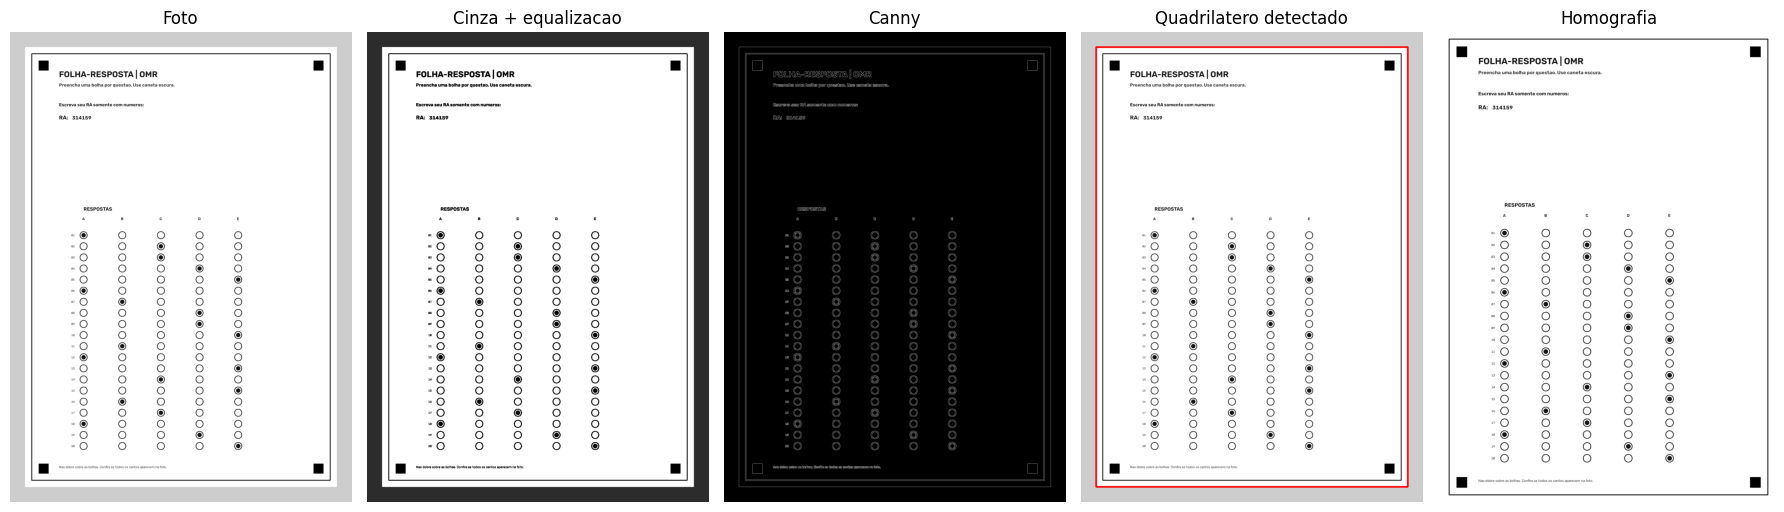

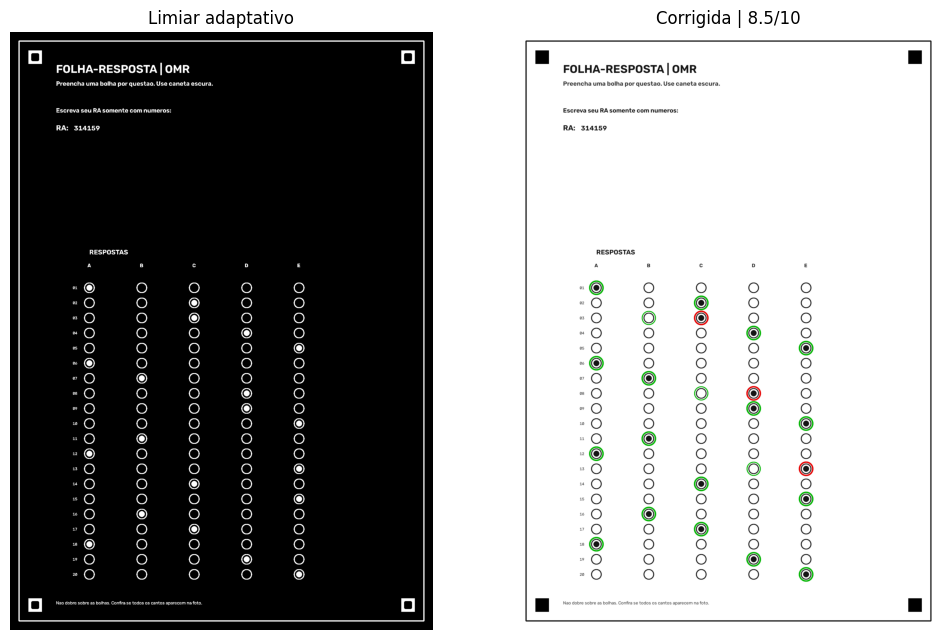

RA lido: ILEGIVEL Nota: 8.5 Respostas: ['A', 'C', 'C', 'D', 'E', 'A', 'B', 'D', 'D', 'E', 'B', 'A', 'E', 'C', 'E', 'B', 'C', 'A', 'D', 'E']


True

In [8]:
def preencher_folha(respostas,matricula='123456'):
    # Demonstração automatizada: imprime dígitos no campo RA; não simula escrita manual real.
    img=gerar_folha()
    cv2.putText(img,str(matricula),(250,385),cv2.FONT_HERSHEY_SIMPLEX,.9,(20,20,20),2,cv2.LINE_AA)
    for q,ch in enumerate(respostas):
        if ch in OPCOES: cv2.circle(img,centro_bolha_questao(q,OPCOES.index(ch)),11,(20,20,20),-1,cv2.LINE_AA)
    return img

rng=random.Random(17)
resp_demo=GABARITO.copy()
for i in [2,7,12]: resp_demo[i]=OPCOES[(OPCOES.index(resp_demo[i])+1)%N_OPCOES]
demo=preencher_folha(resp_demo,'314159')
# Fundo contrastante em volta da folha ajuda o Canny a detectar o contorno externo, sem confundir com a moldura impressa.
demo=cv2.copyMakeBorder(demo,80,80,80,80,cv2.BORDER_CONSTANT,value=(205,205,205))
resultado,ret,etapas,bw=processar_foto(demo)
mostrar_etapas(demo,etapas,ret)
fig,axs=plt.subplots(1,2,figsize=(12,8)); axs[0].imshow(bw,cmap='gray'); axs[0].set_title('Limiar adaptativo')
axs[1].imshow(cv2.cvtColor(resultado['corrigida'],cv2.COLOR_BGR2RGB)); axs[1].set_title(f"Corrigida | {resultado['nota']:.1f}/10")
for ax in axs: ax.axis('off')
plt.show()
print('RA lido:',resultado['ra'],'Nota:',resultado['nota'],'Respostas:',resultado['respostas'])
cv2.imwrite('folha_corrigida_demo.png',resultado['corrigida'])

## 7. Estatísticas de uma turma
Use um item por folha processada. Em produção, inclua identificador anônimo e guarde as imagens originais com acesso restrito. O índice de acerto por questão ignora respostas em branco/duplas no denominador de respostas válidas, mas os totais inválidos são exibidos separadamente.

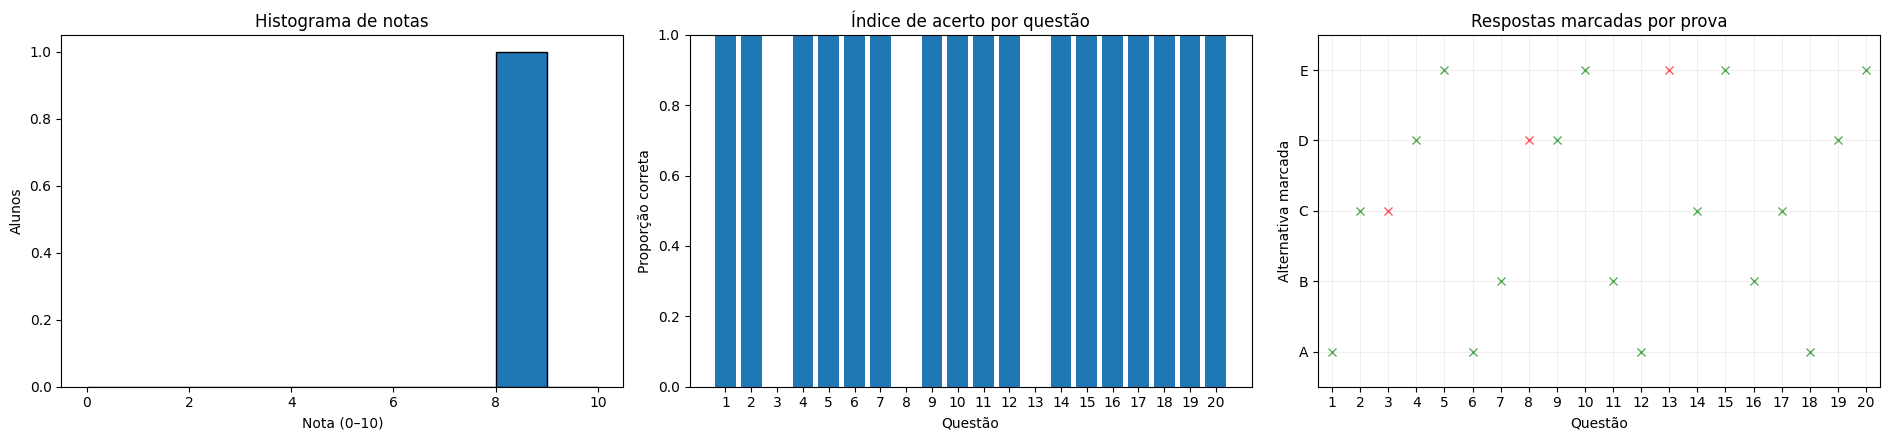

,RA,nota,brancas,duplas
0,ILEGIVEL,8.5,0,0


,questao,indice_acerto
0,1,1.0
1,2,1.0
2,3,0.0
3,4,1.0
4,5,1.0


In [9]:
def montar_estatisticas(resultados,gabarito=GABARITO,csv_path='notas.csv'):
    linhas=[]
    for r in resultados:
        respostas=r['respostas']; validas=[x for x in respostas if x in OPCOES]
        linhas.append({'RA':r['ra'],'nota':r['nota'],'brancas':respostas.count('BRANCO'),'duplas':respostas.count('DUPLA')})
    df=pd.DataFrame(linhas); df.to_csv(csv_path,index=False)
    acerto=[]
    for q,g in enumerate(gabarito):
        vals=[r['respostas'][q] for r in resultados if r['respostas'][q] in OPCOES]
        acerto.append(sum(v==g for v in vals)/len(vals) if vals else np.nan)
    questoes=pd.DataFrame({'questao':np.arange(1,len(gabarito)+1),'indice_acerto':acerto})
    fig,axs=plt.subplots(1,3,figsize=(19,4.5))
    axs[0].hist(df['nota'],bins=np.arange(0,11,1),edgecolor='black'); axs[0].set(xlabel='Nota (0–10)',ylabel='Alunos',title='Histograma de notas')
    axs[1].bar(questoes['questao'],questoes['indice_acerto']); axs[1].set(xlabel='Questão',ylabel='Proporção correta',ylim=(0,1),title='Índice de acerto por questão'); axs[1].set_xticks(questoes['questao'])
    # Cada X representa uma resposta válida; verde = correta e vermelho = incorreta.
    for r in resultados:
        for q,a in enumerate(r['respostas']):
            if a not in OPCOES: continue
            correta=(a==gabarito[q])
            cor='green' if correta else 'red'
            axs[2].plot(q+1,OPCOES.index(a),linestyle='None',marker='x',color=cor,alpha=.65,markersize=6)
    axs[2].set(xlabel='Questão',ylabel='Alternativa marcada',title='Respostas marcadas por prova',xlim=(.5,N_QUESTOES+.5),ylim=(-.5,4.5)); axs[2].set_xticks(range(1,N_QUESTOES+1)); axs[2].set_yticks(range(N_OPCOES),OPCOES); axs[2].grid(axis='both',alpha=.2)
    plt.tight_layout(); plt.show()
    return df,questoes

df_demo,questoes_demo=montar_estatisticas([resultado])
display(df_demo,questoes_demo.head())

## 8. Avaliação quantitativa: erro de leitura
A taxa de erro de leitura é definida como número de respostas incorretamente lidas dividido pelo total de respostas esperadas (questões + dígitos de matrícula). Para fotos reais, informe separadamente erros de leitura do RA e das questões, além de branco/dupla. A rotina abaixo injeta perspectiva, mudança de brilho, gradiente, ruído e desfoque em 30 folhas sintéticas com gabaritos conhecidos. Nessas amostras, os dígitos do RA são impressos por fonte; a taxa sintética não mede reconhecimento de escrita manual. Para avaliação de campo, carregue 30 capturas reais e suas transcrições verdadeiras e use a função `avaliar_lote`. Uma folha que falha ao detectar deve contar como falha, não ser removida do denominador.

In [10]:
def simular_foto(folha,seed=0):
    rng=np.random.default_rng(seed); h,w=folha.shape[:2]
    canvas=np.full((h+180,w+180,3),rng.integers(175,236),np.uint8)
    src=np.float32([[0,0],[w-1,0],[w-1,h-1],[0,h-1]])
    margin=45; dst=np.float32([[margin+rng.integers(-25,30),margin+rng.integers(-20,25)],
      [w+margin+rng.integers(-30,25),margin+rng.integers(-20,35)],
      [w+margin+rng.integers(-25,35),h+margin+rng.integers(-30,25)],
      [margin+rng.integers(-25,30),h+margin+rng.integers(-25,30)]])
    M=cv2.getPerspectiveTransform(src,dst)
    out=cv2.warpPerspective(folha,M,(w+180,h+180),borderMode=cv2.BORDER_CONSTANT,borderValue=(210,210,210))
    # Iluminação suave não uniforme e ruído de sensor.
    yy,xx=np.mgrid[0:out.shape[0],0:out.shape[1]]; grad=1+rng.uniform(-.18,.18)*(xx/out.shape[1]-.5)+rng.uniform(-.14,.14)*(yy/out.shape[0]-.5)
    ruido=rng.normal(0,rng.uniform(0,3),out.shape)
    out=np.clip(out.astype(float)*grad[:,:,None]+ruido,0,255).astype(np.uint8)
    if rng.random()<.7: out=cv2.GaussianBlur(out,(3,3),rng.uniform(0,.9))
    return out

def distancia_edicao(a,b):
    linha=list(range(len(b)+1))
    for i,ca in enumerate(a,1):
        nova=[i]
        for j,cb in enumerate(b,1):
            nova.append(min(nova[-1]+1,linha[j]+1,linha[j-1]+(ca!=cb)))
        linha=nova
    return linha[-1]

def avaliar_lote(capturas,verdades):
    linhas=[]; erros_resp=total_resp=erros_id=total_id=0
    for i,(img,gt) in enumerate(zip(capturas,verdades)):
        try:
            r,_,_,_=processar_foto(img)
            er=sum(a!=b for a,b in zip(r['respostas'],gt['respostas'])); ei=distancia_edicao(r['ra'],gt['ra'])
            erros_resp+=er; total_resp+=N_QUESTOES; erros_id+=ei; total_id+=max(len(gt['ra']),1)
            linhas.append({'amostra':i+1,'status':'ok','erros_respostas':er,'erros_ra':ei})
        except Exception as e:
            erros_resp+=N_QUESTOES; total_resp+=N_QUESTOES; erros_id+=max(len(gt['ra']),1); total_id+=max(len(gt['ra']),1)
            linhas.append({'amostra':i+1,'status':'falha: '+str(e),'erros_respostas':N_QUESTOES,'erros_ra':max(len(gt['ra']),1)})
    detalhe=pd.DataFrame(linhas)
    resumo={'taxa_erro_respostas':erros_resp/total_resp,'taxa_erro_ra':erros_id/total_id,'taxa_erro_total':(erros_resp+erros_id)/(total_resp+total_id),'folhas':len(capturas)}
    return resumo,detalhe

# Conjunto controlado de 30 folhas; RA digitado por fonte, nao manuscrito.
capturas=[]; verdades=[]; rng_eval=random.Random(2026)
for i in range(30):
    matricula=f'{i+1:06d}'
    respostas=[rng_eval.choice(OPCOES) for _ in range(N_QUESTOES)]
    capturas.append(simular_foto(preencher_folha(respostas,matricula),seed=i))
    verdades.append({'ra':matricula,'respostas':respostas})
resumo_eval,detalhe_eval=avaliar_lote(capturas,verdades)
print('RESULTADO DE SIMULACAO (nao equivale a fotos reais):',resumo_eval)
display(detalhe_eval)

RESULTADO DE SIMULACAO (nao equivale a fotos reais): {'taxa_erro_respostas': 0.023333333333333334, 'taxa_erro_ra': 4.644444444444445, 'taxa_erro_total': 1.0897435897435896, 'folhas': 30}


,amostra,status,erros_respostas,erros_ra
0,1,ok,0,24
1,2,ok,0,51
2,3,ok,0,8
3,4,ok,0,32
4,5,ok,0,16
5,6,ok,0,7
6,7,ok,0,27
7,8,ok,0,6
8,9,ok,0,41
9,10,ok,0,22


### Avaliação com fotos reais
Organize as imagens em uma pasta e monte `capturas_reais` (BGR) e `verdades_reais` como lista de dicionários `{'ra': '123456', 'respostas': [...]}`. Registre condições variadas: inclinação, distância, luz uniforme e sombras, modelos de câmera e foco. Preserve uma cópia sem alteração das imagens e não use nomes/documentos reais. Compare a saída automática à transcrição manual revisada.

**Limitações a discutir no relatório:** a localização por maior quadrilátero pode escolher uma borda do fundo ou falhar com fundos sem contraste; a ordenação por soma/diferença pode confundir fotos muito giradas; iluminação localizada, sombras, marcas fracas, apagamentos, rasuras, tinta atravessando o limite e impressão fora de escala alteram as proporções; RAs manuscritos podem ser segmentados ou classificados incorretamente; limiares fixos precisam de calibração e podem variar entre impressoras/canetas. A homografia corrige perspectiva planar, mas não corrige papel curvo. Registre matriz de confusão por questão ou, no mínimo, erros e falhas por condição.

### Fluxo resumido para o relatório
1. Conversão BGR para cinza e equalização: melhora o contraste global.
2. Suavização Gaussiana e Canny: reduz ruído e evidencia bordas.
3. Contornos + aproximação poligonal: seleciona quadrilátero da folha.
4. Homografia: transforma a folha inclinada para coordenadas canônicas.
5. Limiarização adaptativa: separa tinta escura do papel sob iluminação variável.
6. Amostragem em discos internos e proporção de pixels escuros: decide resposta, branco ou dupla.
7. Comparação com gabarito: produz nota e marcações coloridas; pandas/Matplotlib geram CSV e estatísticas.

Inclua no relatório as figuras mostradas nas seções 3, 4 e 6 e os resultados quantitativos da seção 8. Cite a origem dos dados; neste notebook, a folha e as amostras de demonstração são geradas pelo próprio código; o RA sintético é impresso e não representa escrita manual.